![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# Machine Learning II: Classification Models and Metrics
*Data Science & Machine Learning - Week 4, Day 5*

## How to use this notebook

Yesterday you met the scikit-learn workflow with one model, k-nearest neighbours, and one metric, accuracy. Today you meet four more classifiers and the metrics that tell you more than accuracy can.

Most of the lesson uses one problem: predicting which customers of a phone company will leave (churn). Using the same data and the same train/test split for every model lets you compare them fairly at the end.

The slides **5. Supervised Learning** and **5A. Evaluation Metrics** in this folder go with the notebook. The other notebooks and slides in this folder belong to Week 5.

Run the cells in order: later sections reuse the churn data and helpers defined earlier.

## Table of contents

- [Setup](#Setup)
- [1. Nearest neighbours: the decision boundary](#1.-Nearest-neighbours:-the-decision-boundary)
- [2. Churn: a real classification problem](#2.-Churn:-a-real-classification-problem)
    - [The baseline](#The-baseline)
    - [1-NN on the raw features](#1-NN-on-the-raw-features)
- [3. Scaling, and why data snooping matters](#3.-Scaling,-and-why-data-snooping-matters)
    - [Data snooping](#Data-snooping)
- [4. Metrics from the confusion matrix](#4.-Metrics-from-the-confusion-matrix)
    - [Reading the numbers](#Reading-the-numbers)
    - [When to use which metric](#When-to-use-which-metric)
- [5. Logistic regression](#5.-Logistic-regression)
    - [Moving the threshold](#Moving-the-threshold)
- [6. Decision trees](#6.-Decision-trees)
    - [Building intuition on a toy problem](#Building-intuition-on-a-toy-problem)
    - [The splitting criterion](#The-splitting-criterion)
    - [Trees and overfitting](#Trees-and-overfitting)
    - [What the tree learned](#What-the-tree-learned)
    - [Information gain by hand](#Information-gain-by-hand)
- [7. Naive Bayes](#7.-Naive-Bayes)
- [8. Support vector machines](#8.-Support-vector-machines)
    - [Which line is best?](#Which-line-is-best?)
- [9. Comparing the models on churn](#9.-Comparing-the-models-on-churn)
- [Appendix](#Appendix)
    - [A.1 Text classification with Naive Bayes and SVMs](#A.1-Text-classification-with-Naive-Bayes-and-SVMs)
    - [A.2 The maths of the maximum-margin classifier](#A.2-The-maths-of-the-maximum-margin-classifier)

## Setup

The imports for the whole notebook, plus two helpers for the toy examples: `make_blobs3` creates a small two-class dataset, and `plot_boundary` colours the plane by the class a fitted model predicts at each point.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay)


def make_blobs3(n, seed):
    """Red class (+1): blobs around (0, 0) and (8, 5). Blue class (-1): a blob around (5, 5)."""
    rng = np.random.RandomState(seed)
    X = np.concatenate([1.25 * rng.randn(n, 2), 5 + 1.5 * rng.randn(n, 2), [8, 5] + 1.5 * rng.randn(n, 2)])
    y = np.concatenate([np.ones(n), -np.ones(n), np.ones(n)])
    return X, y


def plot_boundary(model, X, y, ax, title="", lims=(-5, 15)):
    """Colour each point of the plane by the class the model predicts there (labels +1 and -1)."""
    xx, yy = np.meshgrid(np.linspace(*lims, 300), np.linspace(*lims, 300))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-2, 0, 2], colors=["tab:blue", "tab:red"], alpha=0.2)
    ax.contour(xx, yy, Z, levels=[0], colors="k", linewidths=1)
    ax.scatter(X[y == 1, 0], X[y == 1, 1], c="tab:red", s=15)
    ax.scatter(X[y == -1, 0], X[y == -1, 1], c="tab:blue", s=15)
    ax.set_title(title)
    ax.set_xlim(lims)
    ax.set_ylim(lims)

## 1. Nearest neighbours: the decision boundary

Nearest neighbours is an *instance-based* (or *lazy*) method: it builds no formula, it keeps the training data. Each training example is a solved case. To classify a new point, it finds the most similar cases and copies their label.

A **decision boundary** is the line (or surface) where the model's prediction switches from one class to the other. Drawing it on a two-feature toy problem shows how flexible a model is.

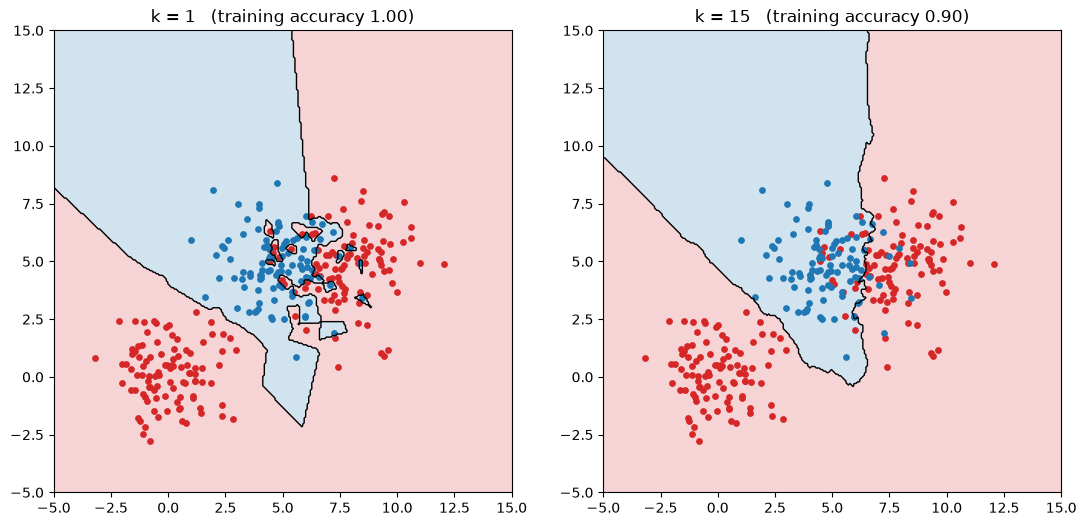

In [2]:
X_toy, y_toy = make_blobs3(100, seed=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, k in zip(axes, [1, 15]):
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_toy, y_toy)
    plot_boundary(knn, X_toy, y_toy, ax, f"k = {k}   (training accuracy {knn.score(X_toy, y_toy):.2f})")
plt.show()

Observations:

+ With **k = 1** the boundary is jagged: it is built from pieces of straight lines halfway between neighbouring points of different classes. Every training point is classified correctly, so training accuracy is 1.00, and adding or removing a single point can move the boundary a lot. The model is very complex.
+ With **k = 15** each prediction is a vote among 15 neighbours. The boundary is smoother and ignores isolated points, at the price of a few training errors.
+ Larger k plays the role of *regularisation*: it limits how complex the model can get. The right k is chosen with validation or cross-validation, as you saw yesterday.
+ Everything depends on the notion of distance, which matters a lot in the next section.

## 2. Churn: a real classification problem

The file `data/churn.csv` describes 3,333 customers of a phone company: their plan, how many minutes they talk during the day, evening and night, how often they call customer service, and whether they left (`Churn?`). The goal is to predict which customers will leave so the company can try to keep them.

We drop the columns that cannot help (state and phone number), turn the yes/no plans into 1/0, and make churn the positive class (1).

In [3]:
churn = pd.read_csv("data/churn.csv")

y = (churn["Churn?"] == "True.").astype(int)
X = churn.drop(columns=["State", "Phone", "Churn?"])
for col in ["Int'l Plan", "VMail Plan"]:
    X[col] = (X[col] == "yes").astype(int)

print(X.shape)
print(f"Share of customers who churn: {y.mean():.3f}")
X.head()

(3333, 18)
Share of customers who churn: 0.145


,Account Length,Area Code,Int'l Plan,VMail Plan,VMail Message,Day Mins,Day Calls,Day Charge,Eve Mins,Eve Calls,Eve Charge,Night Mins,Night Calls,Night Charge,Intl Mins,Intl Calls,Intl Charge,CustServ Calls
0,128,415,0,1,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1
1,107,415,0,1,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1
2,137,415,0,0,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0
3,84,408,1,0,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2
4,75,415,1,0,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3


One split for the whole lesson, stratified so both sets keep the 14.5% churn rate. Every model below is trained on `X_train` and scored on `X_test`.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
print(len(X_train), "training rows,", len(X_test), "test rows,", y_test.sum(), "churners in the test set")

2499 training rows, 834 test rows, 121 churners in the test set


### The baseline

Before judging any model, ask what a model that learns nothing would score. `DummyClassifier(strategy="most_frequent")` always predicts the majority class, "stays".

In [5]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(f"Baseline accuracy: {baseline.score(X_test, y_test):.3f}")

Baseline accuracy: 0.855


85.5% accuracy without catching a single churner. On imbalanced data, accuracy alone is misleading: any model has to beat this number, and even then we need to know *which* customers it gets right.

### 1-NN on the raw features

Accuracy: 0.835


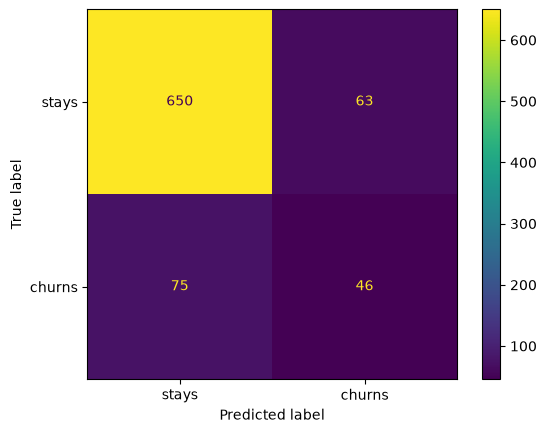

              precision    recall  f1-score   support

       stays       0.90      0.91      0.90       713
      churns       0.42      0.38      0.40       121

    accuracy                           0.83       834
   macro avg       0.66      0.65      0.65       834
weighted avg       0.83      0.83      0.83       834



In [6]:
knn = KNeighborsClassifier(n_neighbors=1).fit(X_train, y_train)
y_pred = knn.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["stays", "churns"])
plt.show()
print(classification_report(y_test, y_pred, target_names=["stays", "churns"]))

The model scores **0.835, worse than the baseline**. The confusion matrix (rows are the true class, columns the prediction) shows it finds 46 of the 121 churners and wrongly flags 63 loyal customers.

`classification_report` lists precision, recall and F1 for each class. Section 4 explains each of them.

## 3. Scaling, and why data snooping matters

KNN uses Euclidean distance, which treats one unit of every feature as equally important. Here that is far from true: `Day Mins` goes up to about 350, while `Int'l Plan` is 0 or 1. The distance is dominated by the large-valued columns and the plans barely count.

**Standardisation** rescales each feature to mean 0 and standard deviation 1, so they all count the same. The scaler learns the mean and standard deviation from the **training set only**, and the same numbers are applied to the test set.

Accuracy after scaling: 0.871


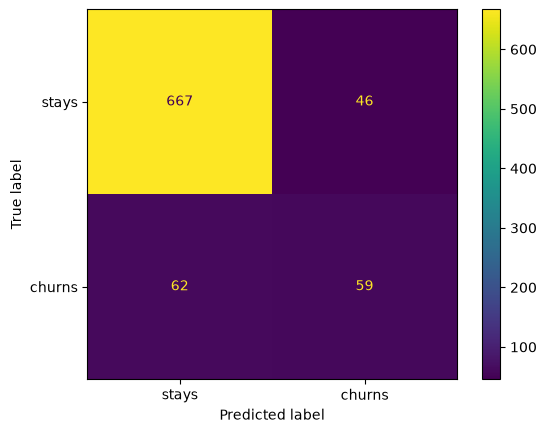

In [7]:
scaler = StandardScaler().fit(X_train)       # learn mean and std on the training data only
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)          # reuse the training mean and std

knn = KNeighborsClassifier(n_neighbors=1).fit(X_train_s, y_train)
y_pred_knn = knn.predict(X_test_s)
print(f"Accuracy after scaling: {accuracy_score(y_test, y_pred_knn):.3f}")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_knn, display_labels=["stays", "churns"])
plt.show()

Accuracy rises from 0.835 to 0.871, now above the baseline, and the model finds 59 churners instead of 46. Same model, same data: only the scale of the features changed.

### Data snooping

**Data snooping** (or *leakage*) means letting information from the data you evaluate on reach the model during training. The score then looks better than the model really is.

A common way to do it by accident: scale the **whole** dataset first, then run cross-validation. Each validation fold has already influenced the mean and standard deviation used to scale the training folds. The right way is to fit the scaler inside each fold. A **pipeline** does that for you: `make_pipeline(StandardScaler(), model)` behaves like one model, and `cross_val_score` refits the scaler on every training fold. You will use pipelines a lot next week.

In [8]:
kf = KFold(n_splits=5, shuffle=True, random_state=0)

X_scaled_all = StandardScaler().fit_transform(X)          # snooping: scaler sees every fold
snooping = cross_val_score(KNeighborsClassifier(n_neighbors=1), X_scaled_all, y, cv=kf)

pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=1))
clean = cross_val_score(pipe, X, y, cv=kf)                 # scaler refit inside each fold

print("Snooping:   ", snooping.round(3), f"mean {snooping.mean():.3f}")
print("No snooping:", clean.round(3), f"mean {clean.mean():.3f}")

Snooping:    [0.867 0.888 0.865 0.871 0.851] mean 0.868
No snooping: [0.865 0.882 0.867 0.872 0.85 ] mean 0.867


Here the difference is tiny: with 3,333 rows the mean and standard deviation barely change whether one fold is included or not. That does not make snooping harmless. When the step that peeks at the data actually *learns* from the target, the effect can be huge.

The next cell creates pure noise: 100 rows, 5,000 random features and random labels. There is nothing to learn, so an honest score should be about 0.5. Selecting the 20 features most related to the target on the whole dataset, and *then* cross-validating, tells a different story.

In [9]:
from sklearn.feature_selection import SelectKBest, f_classif

rng = np.random.RandomState(0)
X_noise = rng.randn(100, 5000)
y_noise = rng.randint(0, 2, 100)

X_selected = SelectKBest(f_classif, k=20).fit_transform(X_noise, y_noise)   # snooping
snooped = cross_val_score(LogisticRegression(max_iter=1000), X_selected, y_noise, cv=5).mean()

pipe = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=1000))
honest = cross_val_score(pipe, X_noise, y_noise, cv=5).mean()

print(f"Feature selection before CV: {snooped:.2f}")
print(f"Feature selection inside CV: {honest:.2f}")

Feature selection before CV: 0.90
Feature selection inside CV: 0.57


**90% accuracy on random noise** with snooping, against 57% (about chance) when the selection happens inside each fold. The rule: every step that learns from data (scaling, feature selection, filling missing values, encoding) is fitted on training data only.

## 4. Metrics from the confusion matrix

For a binary problem with classes 0 and 1, scikit-learn's `confusion_matrix(y_true, y_pred)` has the true classes as rows and the predictions as columns:

|  | predicted 0 | predicted 1 |
| --- | --- | --- |
| **true 0** | TN | FP |
| **true 1** | FN | TP |

+ **True positives (TP):** positive samples predicted as positive (churners we caught).
+ **True negatives (TN):** negative samples predicted as negative (loyal customers left alone).
+ **False positives (FP):** negative samples predicted as positive (loyal customers wrongly flagged).
+ **False negatives (FN):** positive samples predicted as negative (churners we missed).

Which class is "positive" is your choice: pick the one you want to find. Here it is churn.

The metrics combine these four counts:

+ **Accuracy**: the share of all predictions that are right.
$$\text{accuracy}=\frac{\text{TP}+\text{TN}}{\text{TP}+\text{TN}+\text{FP}+\text{FN}}$$
+ **Recall** (sensitivity, true positive rate): of the real positives, how many did we find? It reads along the "true 1" row.
$$\text{recall}=\frac{\text{TP}}{\text{TP}+\text{FN}}$$
+ **Precision** (positive predictive value): of the samples we predicted positive, how many really are? It reads down the "predicted 1" column.
$$\text{precision}=\frac{\text{TP}}{\text{TP}+\text{FP}}$$
+ **Specificity** (true negative rate): of the real negatives, how many did we leave alone?
$$\text{specificity}=\frac{\text{TN}}{\text{TN}+\text{FP}}$$
+ **F1 score**: the harmonic mean of precision and recall. It is only high when both are.
$$F_1 = 2\cdot\frac{\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}$$
+ **Balanced accuracy**: the average of recall and specificity, so each class counts the same however rare it is. Always predicting the majority class scores 0.5.

Let us compute them by hand for the scaled 1-NN model and check them against scikit-learn.

In [10]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_knn).ravel()
print(f"TP={tp}  TN={tn}  FP={fp}  FN={fn}")

print(f"recall      by hand {tp / (tp + fn):.3f}   sklearn {recall_score(y_test, y_pred_knn):.3f}")
print(f"precision   by hand {tp / (tp + fp):.3f}   sklearn {precision_score(y_test, y_pred_knn):.3f}")
print(f"specificity by hand {tn / (tn + fp):.3f}")
print(f"F1                         sklearn {f1_score(y_test, y_pred_knn):.3f}")
print(f"balanced accuracy          sklearn {balanced_accuracy_score(y_test, y_pred_knn):.3f}")

TP=59  TN=667  FP=46  FN=62
recall      by hand 0.488   sklearn 0.488
precision   by hand 0.562   sklearn 0.562
specificity by hand 0.935
F1                         sklearn 0.522
balanced accuracy          sklearn 0.712


### Reading the numbers

+ **Recall 0.488**: the model finds 59 of the 121 customers who leave, about half.
+ **Precision 0.562**: of the 105 customers it flags, 59 really leave. Roughly 4 in 9 retention calls would go to customers who were staying anyway.
+ **Specificity 0.935**: it leaves 667 of the 713 loyal customers alone.
+ **Balanced accuracy 0.712**: much less flattering than the 0.871 accuracy, because it gives the rare churn class the same weight as the common one.

### When to use which metric

+ **Recall** when a false negative is expensive: you want to catch as many positives as possible. Example: medical screening, where missing a disease is far worse than a false alarm that a second test will clear.
+ **Precision** when a false positive is expensive: every positive prediction should be trustworthy. Example: a spam filter, where sending an important email to spam is worse than letting some spam through.
+ **Specificity** when it matters to clear the negatives correctly. Example: confirming that a blood donation is free of a disease before it is used.
+ **F1 or balanced accuracy** when you need one number that does not hide a rare class.

For churn, a missed churner is a lost customer, while a wrongly flagged one only gets a call or a discount. That usually makes recall the priority, as long as precision does not fall so low that the campaign costs more than it saves.

## 5. Logistic regression

Despite its name, logistic regression is a **classifier**. It computes a linear score from the features, like linear regression, and then squeezes that score into a probability between 0 and 1 with the **sigmoid** function:

$$p(\text{churn} \mid x) = \frac{1}{1 + e^{-(b + w_1 x_1 + \dots + w_d x_d)}}$$

The model predicts churn when that probability is at least 0.5. Its decision boundary, where the probability is exactly 0.5, is a straight line (a hyperplane in more dimensions).

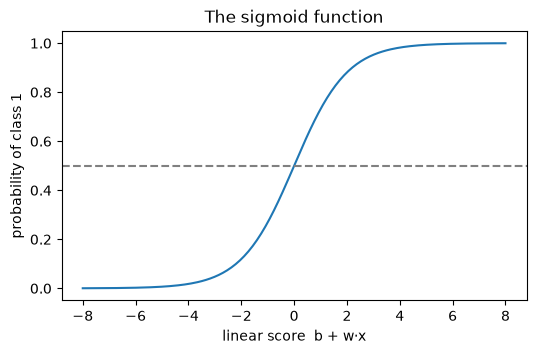

In [11]:
z = np.linspace(-8, 8, 200)
plt.figure(figsize=(6, 3.5))
plt.plot(z, 1 / (1 + np.exp(-z)))
plt.axhline(0.5, color="grey", linestyle="--")
plt.xlabel("linear score  b + w·x")
plt.ylabel("probability of class 1")
plt.title("The sigmoid function")
plt.show()

Logistic regression is fitted by an iterative optimiser, which works best on scaled features, so we use the scaled data. `max_iter=1000` gives the optimiser enough steps to converge.

In [12]:
logreg = LogisticRegression(max_iter=1000).fit(X_train_s, y_train)
y_pred_lr = logreg.predict(X_test_s)
print(f"accuracy {accuracy_score(y_test, y_pred_lr):.3f}   "
      f"recall {recall_score(y_test, y_pred_lr):.3f}   precision {precision_score(y_test, y_pred_lr):.3f}")

accuracy 0.868   recall 0.231   precision 0.622


Accuracy looks fine, but recall is only 0.23: the model finds fewer than a quarter of the churners. Because the features are scaled, the coefficients can be compared: a positive coefficient pushes towards churn, a negative one away from it.

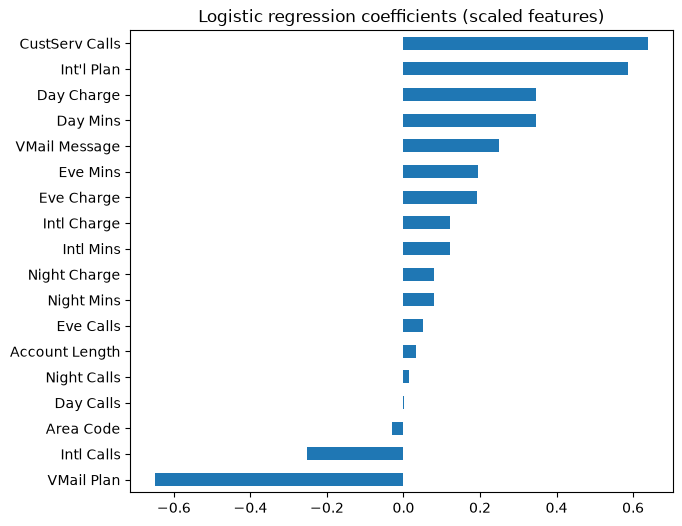

In [13]:
coefs = pd.Series(logreg.coef_[0], index=X.columns).sort_values()
coefs.plot.barh(figsize=(7, 6), title="Logistic regression coefficients (scaled features)")
plt.show()

More calls to customer service and having an international plan push towards churn; having a voicemail plan pushes away from it.

### Moving the threshold

`predict` uses a threshold of 0.5. `predict_proba` returns the probability of each class, so you can pick your own threshold. Lowering it flags more customers: recall goes up and precision goes down.

In [14]:
proba = logreg.predict_proba(X_test_s)[:, 1]   # column 1 = probability of churn
print(proba[:5].round(3))

rows = []
for threshold in [0.5, 0.3, 0.2]:
    y_pred_t = (proba >= threshold).astype(int)
    rows.append({"threshold": threshold,
                 "flagged": y_pred_t.sum(),
                 "accuracy": accuracy_score(y_test, y_pred_t),
                 "recall": recall_score(y_test, y_pred_t),
                 "precision": precision_score(y_test, y_pred_t)})
pd.DataFrame(rows).round(3)

[0.025 0.063 0.047 0.088 0.195]


,threshold,flagged,accuracy,recall,precision
0,0.5,45,0.868,0.231,0.622
1,0.3,115,0.854,0.471,0.496
2,0.2,200,0.807,0.661,0.400


At 0.3 the model finds about twice as many churners (recall 0.47) and half of its flags are right; at 0.2 it finds two thirds of them, but 6 in 10 flags are false alarms. Accuracy falls as the threshold drops, yet for a retention campaign the lower threshold may well be the better choice. The threshold is a business decision, not a fixed part of the model.

Even with a moved threshold, logistic regression struggles here: its boundary is a straight line, and churn seems to depend on combinations of features. The next model handles that naturally.

## 6. Decision trees

A decision tree classifies by asking a sequence of yes/no questions about the features: "Is `Day Charge` above 41.67? If so, does the customer have more than 6 voicemail messages?" Each question splits the data in two; the final groups are called **leaves**, and each leaf predicts the majority class of the training samples that reach it.

+ Each internal node stores one feature and one threshold. The splits are *axis-aligned*: each one cuts along a single feature. That is what makes trees easy to read.
+ A leaf that contains only one class is **pure**. If a leaf is impure, the tree predicts its majority class, and `predict_proba` returns the class shares in the leaf.
+ Trees need no scaling: a threshold on `Day Mins` works the same whatever its units.
+ They handle interactions between features, because each question is asked only within the group created by the previous answers.

### Building intuition on a toy problem

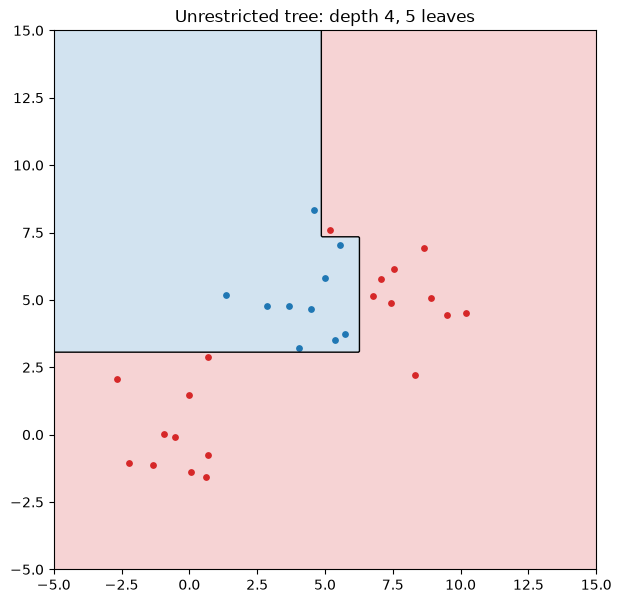

In [15]:
X_small, y_small = make_blobs3(10, seed=2)

full_tree = DecisionTreeClassifier(random_state=0).fit(X_small, y_small)
fig, ax = plt.subplots(figsize=(7, 7))
plot_boundary(full_tree, X_small, y_small, ax, f"Unrestricted tree: depth {full_tree.get_depth()}, {full_tree.get_n_leaves()} leaves")
plt.show()

The boundary is made of horizontal and vertical segments, one for each split. `plot_tree` draws the tree itself. Here is the tree restricted to two levels:

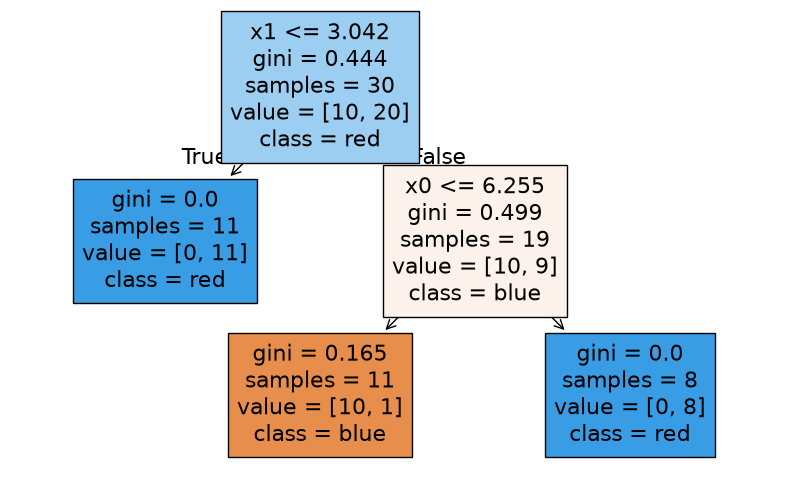

In [16]:
tree_2 = DecisionTreeClassifier(random_state=0, max_depth=2).fit(X_small, y_small)
plt.figure(figsize=(10, 6))
plot_tree(tree_2, feature_names=["x0", "x1"], class_names=["blue", "red"], filled=True)
plt.show()

Each box shows the question, the impurity of the node (`gini`), how many samples reach it, and how many of each class (`value`, blue first).

The first node splits on feature $x_1$ at $3.04$: the 11 points below that line are all red, so the left branch is already a pure leaf. The second node only applies above the line, and splits on $x_0$ at $6.25$. The blue region is therefore described by the rule $(x_1>3.04) \wedge (x_0\leq 6.25)$. The boundaries after one and two levels:

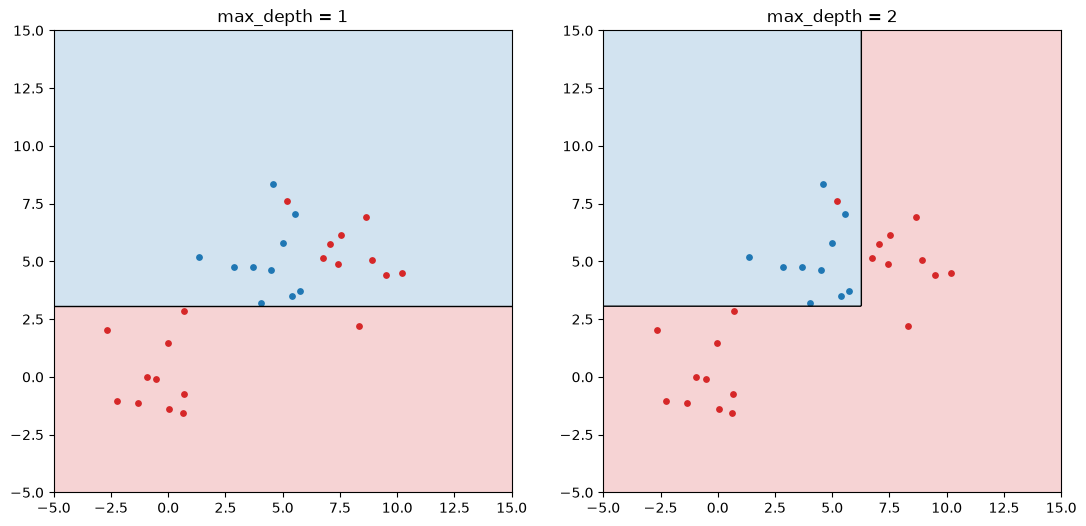

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, depth in zip(axes, [1, 2]):
    t = DecisionTreeClassifier(random_state=0, max_depth=depth).fit(X_small, y_small)
    plot_boundary(t, X_small, y_small, ax, f"max_depth = {depth}")
plt.show()

What is great about decision trees:

+ They are easy for people to interpret: a tree is a set of rules, and each path from the root to a leaf is an AND of thresholds.
+ They are very expressive: given enough depth, a tree can isolate every training point in its own box.
+ Many different trees fit the same data. Finding the smallest one is computationally intractable, so trees are grown **greedily**: at each node, pick the best split right now without looking ahead.

### The splitting criterion

To choose "the best split", the tree measures the **impurity** of a node. The two common measures:

+ **Gini index**: the chance that two samples drawn at random from the node belong to different classes.
$$\text{Gini}=1-\sum_i p_i^2$$
+ **Entropy**: the average surprise of the class labels in the node.
$$\text{Entropy}=-\sum_i p_i\log_2 p_i$$

Both are 0 for a pure node and largest when the classes are equally mixed. A split is chosen to make the children, on average, as pure as possible. With entropy, the reduction is called **information gain**:

$$\text{IG} = H(\text{parent}) - \sum_{\text{children}} \frac{n_\text{child}}{n_\text{parent}}\, H(\text{child})$$

The plot shows both measures for a node with a share $p$ of one class (entropy is halved so both curves peak at 0.5):

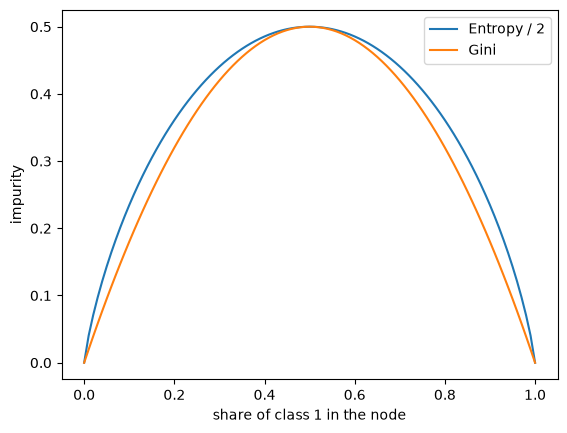

In [18]:
def entropy(p):
    p = np.asarray(p, dtype=float)
    p = p[p > 0]                      # 0 * log(0) counts as 0
    return -np.sum(p * np.log2(p))

def gini(p):
    return 1 - np.sum(np.asarray(p) ** 2)

pvals = np.linspace(0, 1, 101)
plt.plot(pvals, [entropy([p, 1 - p]) / 2 for p in pvals], label="Entropy / 2")
plt.plot(pvals, [gini([p, 1 - p]) for p in pvals], label="Gini")
plt.xlabel("share of class 1 in the node")
plt.ylabel("impurity")
plt.legend()
plt.show()

### Trees and overfitting

Because trees can carve out a box for every training point, an unrestricted tree fits the training set perfectly and easily overfits. There are two ways to stop that:

+ **Stop growing early** with `max_depth` (how many questions in a row), `min_samples_leaf` (the smallest group a leaf may contain) or `min_samples_split`.
+ **Grow a full tree and prune it back.** scikit-learn implements *cost-complexity pruning* through the `ccp_alpha` parameter: the larger it is, the more branches are removed.

Let us see it on churn. Trees do not need scaled features, so they use the raw `X_train`.

In [19]:
rows = []
for depth in [None, 3, 5]:
    t = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(X_train, y_train)
    y_pred_t = t.predict(X_test)
    rows.append({"max_depth": str(depth), "depth": t.get_depth(), "leaves": t.get_n_leaves(),
                 "train accuracy": t.score(X_train, y_train), "test accuracy": accuracy_score(y_test, y_pred_t),
                 "recall": recall_score(y_test, y_pred_t), "precision": precision_score(y_test, y_pred_t)})
pd.DataFrame(rows).round(3)

,max_depth,depth,leaves,train accuracy,test accuracy,recall,precision
0,None,23,172,1.000,0.920,0.785,0.699
1,3,3,8,0.903,0.914,0.537,0.802
2,5,5,26,0.954,0.959,0.802,0.907


+ The unrestricted tree grows 23 levels and 172 leaves, scores 1.00 on the training data and 0.920 on the test set: textbook overfitting.
+ Depth 3 is too simple and loses recall.
+ **Depth 5** scores 0.959 on the test set and finds 80% of the churners with 91% precision, far better than KNN or logistic regression. Churn depends on combinations of features, and that is exactly what a tree models.

In practice, choose `max_depth` with cross-validation, as you chose k for KNN.

### What the tree learned

`feature_importances_` measures how much each feature reduced impurity across all the splits that used it.

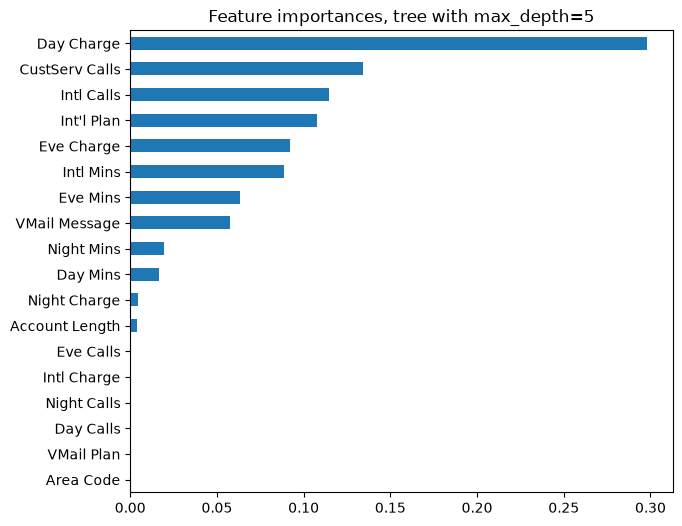

In [20]:
tree_5 = DecisionTreeClassifier(max_depth=5, random_state=0).fit(X_train, y_train)
importances = pd.Series(tree_5.feature_importances_, index=X.columns).sort_values()
importances.plot.barh(figsize=(7, 6), title="Feature importances, tree with max_depth=5")
plt.show()

A depth-3 tree trained with entropy is small enough to read:

Test accuracy: 0.911


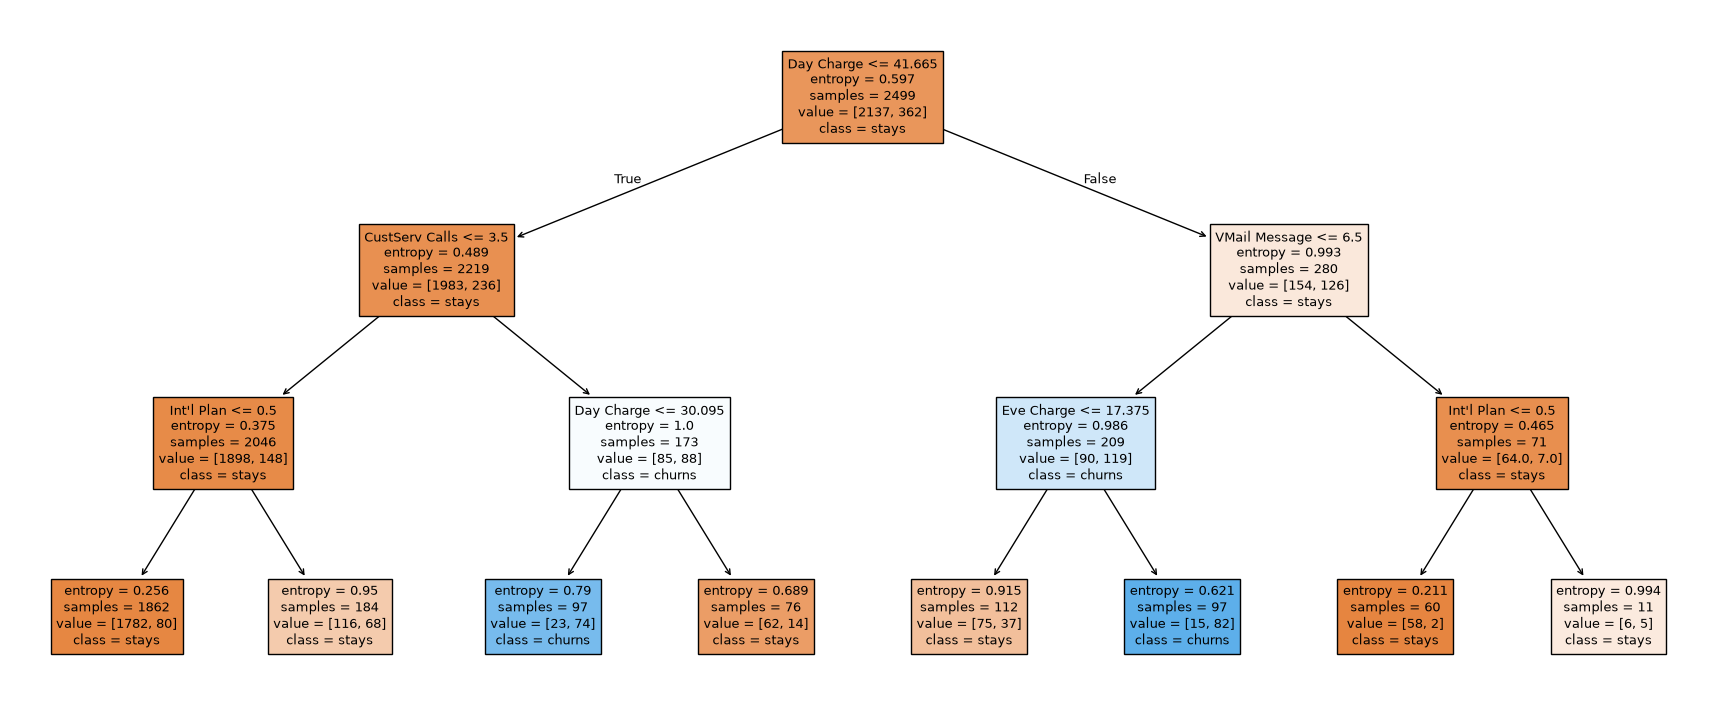

In [21]:
tree_3 = DecisionTreeClassifier(max_depth=3, criterion="entropy", random_state=0).fit(X_train, y_train)
print(f"Test accuracy: {tree_3.score(X_test, y_test):.3f}")

plt.figure(figsize=(22, 9))
plot_tree(tree_3, feature_names=list(X.columns), class_names=["stays", "churns"], filled=True, fontsize=9)
plt.show()

Two leaves are mostly churners:

+ $(\text{Day Charge} \leq 41.67) \wedge (\text{CustServ Calls} > 3.5) \wedge (\text{Day Charge} \leq 30.10)$: customers who use the phone little and have called customer service four times or more. 74 of the 97 training customers in this leaf left.
+ $(\text{Day Charge} > 41.67) \wedge (\text{VMail Message} \leq 6.5) \wedge (\text{Eve Charge} > 17.38)$: heavy daytime and evening users who barely use voicemail. 82 of the 97 left.

Neither rule is a straight line through the feature space, which is why logistic regression missed so many churners.

### Information gain by hand

Let us recompute the root split from the training data and check that it lowers the entropy.

In [22]:
feature = X.columns[tree_3.tree_.feature[0]]
threshold = tree_3.tree_.threshold[0]
left = X_train[feature] <= threshold
print(f"Root split: {feature} <= {threshold:.2f}")

def class_shares(labels):
    return labels.value_counts(normalize=True).values

n, n_left, n_right = len(y_train), left.sum(), (~left).sum()
H_root = entropy(class_shares(y_train))
H_left = entropy(class_shares(y_train[left]))
H_right = entropy(class_shares(y_train[~left]))

print(f"Root:  {n} samples, churn share {y_train.mean():.3f}, entropy {H_root:.3f}")
print(f"Left:  {n_left} samples, churn share {y_train[left].mean():.3f}, entropy {H_left:.3f}")
print(f"Right: {n_right} samples, churn share {y_train[~left].mean():.3f}, entropy {H_right:.3f}")

H_children = n_left / n * H_left + n_right / n * H_right
print(f"Weighted entropy of the children: {H_children:.3f}")
print(f"Information gain: {H_root - H_children:.3f}")

Root split: Day Charge <= 41.67
Root:  2499 samples, churn share 0.145, entropy 0.597
Left:  2219 samples, churn share 0.106, entropy 0.489
Right: 280 samples, churn share 0.450, entropy 0.993
Weighted entropy of the children: 0.545
Information gain: 0.052


The children are, on average, purer than the root, so the information gain is positive. The tree tried every feature and every threshold and this split gave the largest gain. The sample counts match the boxes in the plot above.

## 7. Naive Bayes

Naive Bayes is a probabilistic classifier. It predicts the class $y$ that is most likely given the features $x$, using **Bayes' theorem** from Day 1:

$$p(y \mid x) = \frac{p(x \mid y)\,p(y)}{p(x)}$$

+ $p(y)$ is how common each class is.
+ $p(x \mid y)$ is how likely these feature values are within each class.
+ $p(x)$ is the same for every class, so it does not change which class wins and can be ignored.

The **naive** part: it assumes the features are independent within each class, so $p(x \mid y)$ becomes a simple product $p(x_1 \mid y)\,p(x_2 \mid y)\cdots p(x_d \mid y)$. That is rarely true, but it makes the model very fast, it needs little data, and it works surprisingly well, especially on text.

Different versions model $p(x_i \mid y)$ differently: **GaussianNB** assumes each numeric feature follows a normal distribution within each class; **BernoulliNB** and **MultinomialNB** are made for word presence and word counts in text (see the appendix).

[StatQuest: Naive Bayes, clearly explained](https://www.youtube.com/watch?v=O2L2Uv9pdDA)

Mean of each feature per class:
        x0    x1
-1.0  5.05  5.66
 1.0 -0.01 -0.07


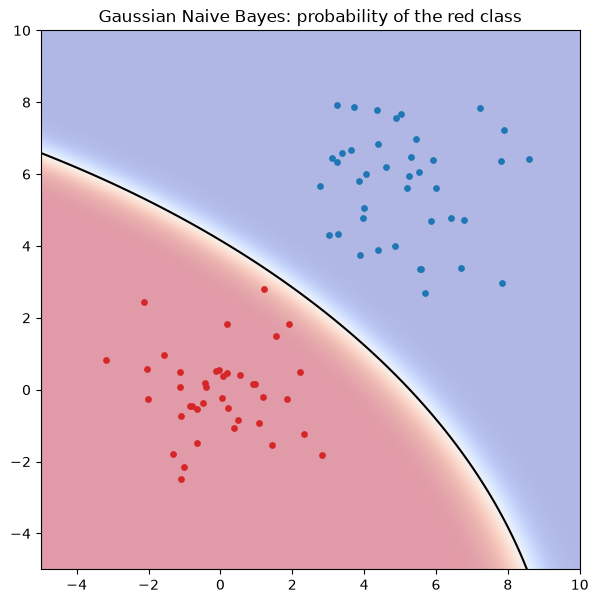

In [23]:
rng = np.random.RandomState(0)
X_nb = np.concatenate([1.25 * rng.randn(40, 2), 5 + 1.5 * rng.randn(40, 2)])
y_nb = np.concatenate([np.ones(40), -np.ones(40)])

nb = GaussianNB().fit(X_nb, y_nb)
print("Mean of each feature per class:")
print(pd.DataFrame(nb.theta_, index=nb.classes_, columns=["x0", "x1"]).round(2))

xx, yy = np.meshgrid(np.linspace(-5, 10, 300), np.linspace(-5, 10, 300))
proba_red = nb.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)   # classes_ = [-1, 1]

plt.figure(figsize=(7, 7))
plt.imshow(proba_red, origin="lower", extent=(-5, 10, -5, 10), cmap="coolwarm", alpha=0.4, vmin=0, vmax=1)
plt.contour(xx, yy, proba_red, levels=[0.5], colors="k")
plt.scatter(X_nb[y_nb == 1, 0], X_nb[y_nb == 1, 1], c="tab:red", s=15)
plt.scatter(X_nb[y_nb == -1, 0], X_nb[y_nb == -1, 1], c="tab:blue", s=15)
plt.title("Gaussian Naive Bayes: probability of the red class")
plt.show()

+ The background shows the predicted probability of the red class: Naive Bayes gives a degree of certainty, not just a label.
+ The black line is where that probability is 0.5: the decision boundary.
+ The boundary is curved because the two classes have different spreads. Gaussian Naive Bayes boundaries are quadratic in general and only become straight lines when the classes have the same variances.

On churn, Gaussian Naive Bayes does not need scaled features, because it models each feature on its own scale:

In [24]:
gnb = GaussianNB().fit(X_train, y_train)
y_pred_nb = gnb.predict(X_test)
print(f"accuracy {accuracy_score(y_test, y_pred_nb):.3f}   "
      f"recall {recall_score(y_test, y_pred_nb):.3f}   precision {precision_score(y_test, y_pred_nb):.3f}")

accuracy 0.879   recall 0.603   precision 0.579


## 8. Support vector machines

![SVM margin](https://upload.wikimedia.org/wikipedia/commons/thumb/7/72/SVM_margin.png/300px-SVM_margin.png)

A support vector machine (SVM) looks for the boundary that separates the classes **with the widest possible margin**: the widest "street" between the classes, whose edges just touch the closest points of each class. Those closest points are the **support vectors**.

When many lines separate the training data, why prefer the widest street? A boundary far from both classes leaves room for new points that land a little off their class, so it should be more robust to noise.

### Which line is best?

Any straight line can be written $w_0 x_0 + w_1 x_1 + \text{offset} = 0$. Here are three candidates on the same data. All three separate the training points perfectly. Which one would you trust with new data?

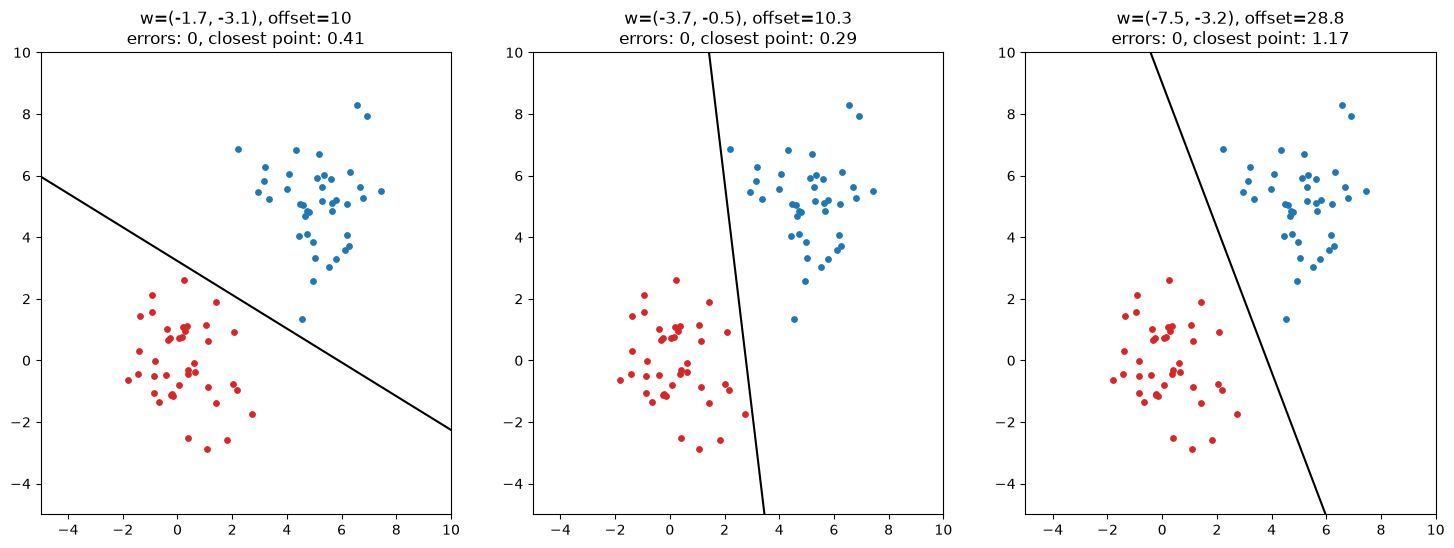

In [25]:
rng = np.random.RandomState(1)
X_svm = np.concatenate([1.25 * rng.randn(40, 2), 5 + 1.5 * rng.randn(40, 2)])
y_svm = np.concatenate([np.ones(40), -np.ones(40)])

candidates = [(-1.7, -3.1, 10), (-3.7, -0.5, 10.3), (-7.5, -3.2, 28.8)]
xs = np.linspace(-5, 10, 100)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (w0, w1, offset) in zip(axes, candidates):
    scores = X_svm @ np.array([w0, w1]) + offset
    errors = (np.sign(scores) != y_svm).sum()
    closest = np.min(np.abs(scores)) / np.hypot(w0, w1)   # distance of the closest point to the line
    ax.scatter(X_svm[y_svm == 1, 0], X_svm[y_svm == 1, 1], c="tab:red", s=15)
    ax.scatter(X_svm[y_svm == -1, 0], X_svm[y_svm == -1, 1], c="tab:blue", s=15)
    ax.plot(xs, -(w0 * xs + offset) / w1, "k")
    ax.set_xlim(-5, 10)
    ax.set_ylim(-5, 10)
    ax.set_title(f"w=({w0}, {w1}), offset={offset}\nerrors: {errors}, closest point: {closest:.2f}")
plt.show()

All three make no errors, but the first two pass close to some points (0.41 and 0.29 units away). The third keeps every point at least 1.17 units away: it has the widest margin, so it is the one to trust.

An SVM finds that line automatically. `SVC(kernel="linear")` fits a straight-line SVM:

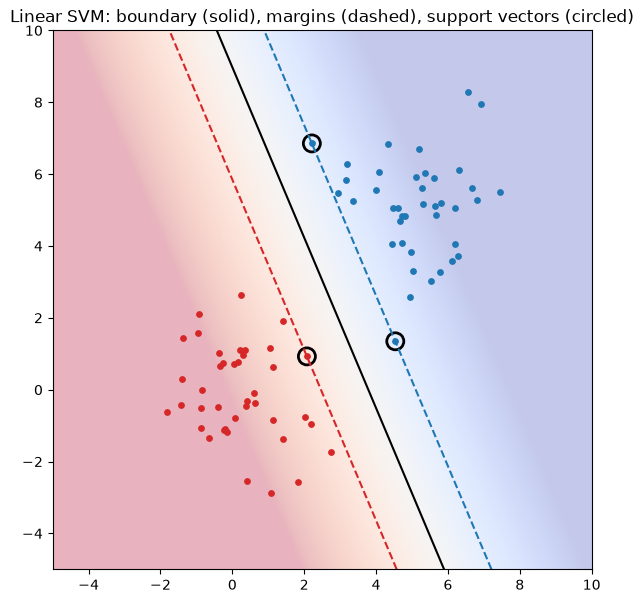

Support vectors per class: [2 1]
Width of half the street: 1.215
(w0, w1) x 10 = [-7.58 -3.2 ]   offset x 10 = 28.7


In [26]:
svm = SVC(kernel="linear").fit(X_svm, y_svm)

fig, ax = plt.subplots(figsize=(7, 7))
xx, yy = np.meshgrid(np.linspace(-5, 10, 300), np.linspace(-5, 10, 300))
Z = svm.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
ax.imshow(Z, origin="lower", extent=(-5, 10, -5, 10), cmap="coolwarm", alpha=0.3, vmin=-3, vmax=3)
ax.contour(xx, yy, Z, levels=[-1, 0, 1], colors=["tab:blue", "k", "tab:red"], linestyles=["--", "-", "--"])
ax.scatter(X_svm[y_svm == 1, 0], X_svm[y_svm == 1, 1], c="tab:red", s=15)
ax.scatter(X_svm[y_svm == -1, 0], X_svm[y_svm == -1, 1], c="tab:blue", s=15)
ax.scatter(*svm.support_vectors_.T, s=150, facecolors="none", edgecolors="k", linewidths=2)
ax.set_title("Linear SVM: boundary (solid), margins (dashed), support vectors (circled)")
plt.show()

print("Support vectors per class:", svm.n_support_)
print("Width of half the street:", round(1 / np.linalg.norm(svm.coef_[0]), 3))
print("(w0, w1) x 10 =", (10 * svm.coef_[0]).round(2), "  offset x 10 =", round(10 * svm.intercept_[0], 2))

+ Only **3 points** (circled) decide where the boundary goes: these are the support vectors. Remove any other point and the boundary does not move; remove a support vector and it does. The model only needs to store these points.
+ The margin is 1.22 units on each side, a little wider than our best guess.
+ Multiplying all the weights by the same number describes the same line, so the coefficients are scaled by 10 to compare with the candidates: the SVM found almost exactly the third line.

Real data is rarely perfectly separable. The parameter **C** controls how much the SVM tolerates points inside the margin or on the wrong side: a small C allows more violations and a wider street (simpler model); a large C tries hard to classify every training point (more complex model). Like k in KNN, C is chosen with cross-validation.

SVMs can also draw curved boundaries with a **kernel**, such as `SVC(kernel="rbf")`, the default. The idea is to map the data into a space where a straight boundary does exist. Week 5 looks at non-linear models in more detail.

[StatQuest: Support Vector Machines](https://www.youtube.com/watch?v=efR1C6CvhmE)

In [27]:
for kernel in ["linear", "rbf"]:
    model = SVC(kernel=kernel).fit(X_train_s, y_train)
    y_pred_svm = model.predict(X_test_s)
    print(f"{kernel:6}  accuracy {accuracy_score(y_test, y_pred_svm):.3f}   recall {recall_score(y_test, y_pred_svm):.3f}   "
          f"churners predicted {y_pred_svm.sum()}")

linear  accuracy 0.855   recall 0.000   churners predicted 0
rbf     accuracy 0.926   recall 0.587   churners predicted 83


The linear SVM predicts that **nobody** churns: no straight line separates churners well enough to be worth it, so its accuracy equals the baseline. The RBF kernel draws a curved boundary and finds about 6 in 10 churners. Like KNN, SVMs depend on distances, so they use the scaled features.

## 9. Comparing the models on churn

Every model trained on the same training set and scored on the same test set, with the metrics from section 4. Models that rely on distances or on an optimiser get the scaled features; the tree and Naive Bayes get the raw ones.

In [28]:
models = {
    "Baseline (always 'stays')": (DummyClassifier(strategy="most_frequent"), False),
    "KNN, k=5": (KNeighborsClassifier(n_neighbors=5), True),
    "Logistic regression": (LogisticRegression(max_iter=1000), True),
    "Decision tree, max_depth=5": (DecisionTreeClassifier(max_depth=5, random_state=0), False),
    "Gaussian Naive Bayes": (GaussianNB(), False),
    "SVM, linear kernel": (SVC(kernel="linear"), True),
    "SVM, RBF kernel": (SVC(kernel="rbf"), True),
}

rows = []
for name, (model, scaled) in models.items():
    Xtr, Xte = (X_train_s, X_test_s) if scaled else (X_train, X_test)
    y_pred_m = model.fit(Xtr, y_train).predict(Xte)
    rows.append({"model": name,
                 "accuracy": accuracy_score(y_test, y_pred_m),
                 "balanced accuracy": balanced_accuracy_score(y_test, y_pred_m),
                 "precision": precision_score(y_test, y_pred_m, zero_division=0),
                 "recall": recall_score(y_test, y_pred_m),
                 "F1": f1_score(y_test, y_pred_m)})

comparison = pd.DataFrame(rows).set_index("model").round(3)
comparison

,accuracy,balanced accuracy,precision,recall,F1
model,,,,,
Baseline (always 'stays'),0.855,0.500,0.000,0.000,0.000
"KNN, k=5",0.894,0.674,0.800,0.364,0.500
Logistic regression,0.868,0.604,0.622,0.231,0.337
"Decision tree, max_depth=5",0.959,0.894,0.907,0.802,0.851
Gaussian Naive Bayes,0.879,0.764,0.579,0.603,0.591
"SVM, linear kernel",0.855,0.500,0.000,0.000,0.000
"SVM, RBF kernel",0.926,0.785,0.855,0.587,0.696


+ **Accuracy hides a lot**: the baseline and the linear SVM both score 0.855 while catching no churner at all. Balanced accuracy and F1 expose them immediately.
+ **The decision tree wins clearly** on every metric. Churn depends on combinations of features (heavy users without voicemail, frequent callers of customer service), which a tree captures with a few questions.
+ **The RBF SVM** is second best: it can draw curved boundaries too, but it is much harder to explain to the business than a tree.
+ **Linear models** (logistic regression and the linear SVM) struggle because no straight line separates the churners. Moving the threshold helps logistic regression, as section 5 showed.
+ **KNN and Naive Bayes** sit in between, with different trade-offs: KNN is more precise, Naive Bayes finds more churners.

The model that wins depends on the problem. That is why you compare several, on the same split, with the metric that matches the business goal. One test split is still one random draw: before trusting small differences, compare the models with cross-validation.

Next week you will tune these models properly with grid search and pipelines, deal with imbalanced classes, and meet ensembles of trees.

## Appendix

Extra material for students who want to go further. It is not needed for the lab.

### A.1 Text classification with Naive Bayes and SVMs

Naive Bayes and linear SVMs are classic choices for classifying text. This example predicts the topic of New York Times front-page stories (1996 to 2006) from their headline. The data was compiled by Amber E. Boydstun and coded with the Policy Agendas topics:

| Code | Topic | Code | Topic |
| --- | --- | --- | --- |
| 1 | Macroeconomics | 16 | Defense |
| 2 | Civil rights, minority issues and civil liberties | 17 | Space, science, technology and communications |
| 3 | Health | 18 | Foreign trade |
| 4 | Agriculture | 19 | International affairs and foreign aid |
| 5 | Labor, employment and immigration | 20 | Government operations |
| 6 | Education | 21 | Public lands and water management |
| 7 | Environment | 24 | State and local government administration |
| 8 | Energy | 26 | Weather and natural disasters |
| 10 | Transportation | 27 | Fires |
| 12 | Law, crime and family issues | 28 | Arts and entertainment |
| 13 | Social welfare | 29 | Sports and recreation |
| 14 | Community development and housing | 30 | Death notices |
| 15 | Banking, finance and domestic commerce | 31 | Churches and religion |
|  |  | 99 | Other, miscellaneous and human interest |

#### Representing a document: bag of words

A model needs numbers, so each headline becomes a row of a big table with one column per word in the vocabulary. In the **bag-of-words** representation the value is how many times the word appears (or just whether it appears). Word order is lost: "the treasure is on the ship" and "the ship is on the treasure" look the same, but for sorting documents by topic that is usually fine.

| Story | ship | treasure | wand | spell |
| --- | --- | --- | --- | --- |
| 1 (pirates) | 3 | 2 | 0 | 0 |
| 2 (pirates) | 2 | 1 | 0 | 1 |
| 3 (wizards) | 0 | 0 | 2 | 3 |
| 4 (wizards) | 0 | 1 | 3 | 2 |

#### Naive Bayes for text

The class probability is proportional to the prior times the product of the word probabilities:

$$p(y \mid x) \propto p(y)\prod_{i=1}^N p(x_i \mid y)$$

Two classic versions differ in what they model:

+ **Multinomial Naive Bayes** models the word *counts* of the document: only the words that appear contribute.
+ **Bernoulli Naive Bayes** models the *presence or absence* of every word in the vocabulary: missing words count too.

Each $p(x_i = 1 \mid y)$ is estimated as the share of documents of class $y$ that contain word $i$. Two practical corrections:

+ **Laplace smoothing.** A word never seen in a class would get probability 0 and veto that class on its own. Adding 1 to every count avoids it:
$$p(x_i=1 \mid y=c) = \frac{\#\text{docs of class } c \text{ containing word } i + 1}{\#\text{docs of class } c + 2}$$
+ **Log probabilities.** Multiplying thousands of small probabilities underflows to 0 in floating point, so the model adds logarithms instead: $\log p(x \mid y) = \sum_i \log p(x_i \mid y)$. The winning class does not change.

#### The data

We train on stories published before 2004 and test on 2004 to 2006: a split in time, like predicting next year's stories.

In [29]:
nyt = pd.read_csv("data/Boydstun_NYT_FrontPage_Dataset_1996-2006_0.csv")
split = pd.to_datetime(nyt["Date"]) < pd.Timestamp(2004, 1, 1)

titles_train, titles_test = nyt.loc[split, "Title"], nyt.loc[~split, "Title"]
topic_train, topic_test = nyt.loc[split, "Topic_2digit"], nyt.loc[~split, "Topic_2digit"]
print(len(titles_train), "training headlines,", len(titles_test), "test headlines,", nyt["Topic_2digit"].nunique(), "topics")
nyt[["Date", "Title", "Topic_2digit"]].head()

23584 training headlines, 7450 test headlines, 27 topics


,Date,Title,Topic_2digit
0,1/1/1996,Nation's Smaller Jails Struggle To Cope With S...,12
1,1/1/1996,Dancing (and Kissing) In the New Year,28
2,1/1/1996,Forbes's Silver Bullet for the Nation's Malaise,20
3,1/1/1996,"Up at Last, Bridge to Bosnia Is Swaying Gatewa...",16
4,1/1/1996,2 SIDES IN SENATE DISAGREE ON PLAN TO END FURL...,20


`CountVectorizer` turns text into a bag of words. It lowercases, strips punctuation and accents, splits into words, drops very common English words (`stop_words="english"`), and keeps words that appear in at least 2 documents (`min_df=2`). Like a scaler, it learns its vocabulary from the training set only.

In [30]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(min_df=2, stop_words="english", strip_accents="unicode")

example = titles_train.iloc[0]
print("Example:  ", example)
print("Tokenized:", vectorizer.build_tokenizer()(example))
print("Analyzed: ", vectorizer.build_analyzer()(example))

X_text_train = vectorizer.fit_transform(titles_train)   # learn the vocabulary on training headlines
X_text_test = vectorizer.transform(titles_test)
print("Matrix shape:", X_text_train.shape)
print("Some words:", vectorizer.get_feature_names_out()[1000:1015])

Example:   Nation's Smaller Jails Struggle To Cope With Surge in Inmates 
Tokenized: ['Nation', 'Smaller', 'Jails', 'Struggle', 'To', 'Cope', 'With', 'Surge', 'in', 'Inmates']
Analyzed:  ['nation', 'smaller', 'jails', 'struggle', 'cope', 'surge', 'inmates']
Matrix shape: (23584, 8950)
Some words: ['boeing' 'boiling' 'boils' 'bold' 'bolster' 'bolsters' 'bolt' 'bolts'
 'bomb' 'bombay' 'bombed' 'bomber' 'bombers' 'bombing' 'bombings']


Accuracy: 0.435


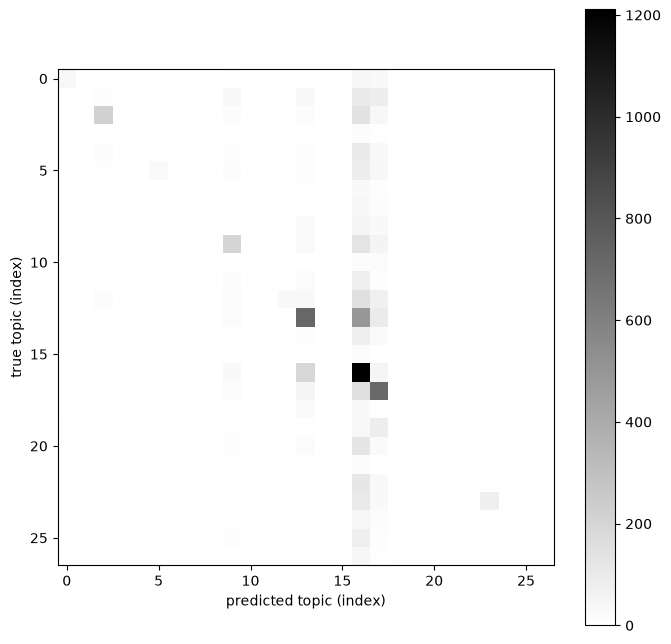

In [31]:
from sklearn.naive_bayes import BernoulliNB

bnb = BernoulliNB().fit(X_text_train, topic_train)
topic_pred = bnb.predict(X_text_test)
print(f"Accuracy: {accuracy_score(topic_test, topic_pred):.3f}")

plt.figure(figsize=(8, 8))
plt.imshow(confusion_matrix(topic_test, topic_pred), cmap="gray_r")
plt.xlabel("predicted topic (index)")
plt.ylabel("true topic (index)")
plt.colorbar()
plt.show()

With 27 topics, guessing at random would be right under 4% of the time, and always predicting the most common topic (international affairs) about 20%. 43% from headlines alone is a real signal. The model also tells us which words it relies on: the words most likely to appear in each topic.

In [32]:
words = vectorizer.get_feature_names_out()
for label, log_probs in list(zip(bnb.classes_, bnb.feature_log_prob_))[:8]:
    top = np.argsort(log_probs)[-5:][::-1]
    print(f"Topic {label:2}: {[words[j] for j in top]}")

Topic  1: ['tax', 'budget', 'economy', 'bush', 'cut']
Topic  2: ['abortion', 'court', 'new', 'gay', 'race']
Topic  3: ['new', 'health', 'drug', 'medicare', 'care']
Topic  4: ['food', 'farmers', 'new', 'safety', 'farm']
Topic  5: ['new', 'immigrants', 'union', 'strike', 'workers']
Topic  6: ['schools', 'school', 'new', 'city', 'students']
Topic  7: ['pollution', 'new', 'air', 'warming', 'rules']
Topic  8: ['oil', 'energy', 'power', 'california', 'blackout']


Headlines are short. Adding the summary of each article gives the model much more to work with:

In [33]:
text = nyt["Title"] + " " + nyt["Summary"]
vectorizer_full = CountVectorizer(min_df=2, stop_words="english", strip_accents="unicode")
X_full_train = vectorizer_full.fit_transform(text[split])
X_full_test = vectorizer_full.transform(text[~split])

bnb_full = BernoulliNB().fit(X_full_train, topic_train)
print(f"Naive Bayes, headline + summary: {bnb_full.score(X_full_test, topic_test):.3f}")

Naive Bayes, headline + summary: 0.553


#### A linear SVM on the same text

`LinearSVC` is a fast linear SVM made for large, sparse data like bag-of-words matrices. With thousands of word features, text is often close to linearly separable, which suits a linear SVM well.

In [34]:
from sklearn.svm import LinearSVC

lsvc = LinearSVC().fit(X_full_train, topic_train)
print(f"Linear SVM, default C: {lsvc.score(X_full_test, topic_test):.3f}")

Linear SVM, default C: 0.666


`GridSearchCV` tries each value of C with 5-fold cross-validation on the training set, keeps the best one, and refits it on the whole training set. This takes about a minute.

Best C: 0.05
Best cross-validated accuracy: 0.721
Test accuracy with the best C: 0.701


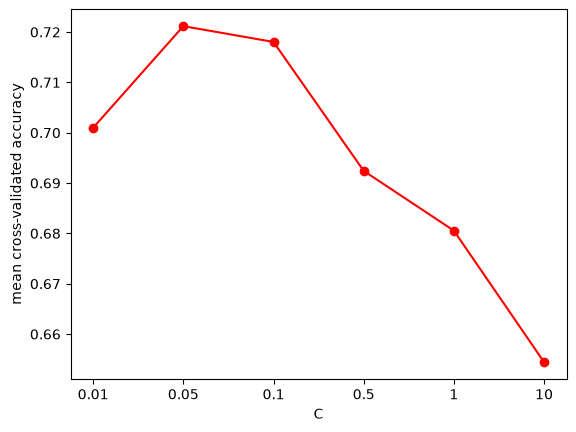

In [35]:
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(LinearSVC(), {"C": [0.01, 0.05, 0.1, 0.5, 1, 10]}, cv=5)
grid.fit(X_full_train, topic_train)

print("Best C:", grid.best_params_["C"])
print(f"Best cross-validated accuracy: {grid.best_score_:.3f}")
print(f"Test accuracy with the best C: {grid.score(X_full_test, topic_test):.3f}")

plt.plot([str(c) for c in grid.param_grid["C"]], grid.cv_results_["mean_test_score"], "o-r")
plt.xlabel("C")
plt.ylabel("mean cross-validated accuracy")
plt.show()

Too small a C oversimplifies; too large a C overfits the training headlines. `best_score_` is the mean cross-validated accuracy of the best C on the training data, and the test score confirms it on stories the model never saw.

### A.2 The maths of the maximum-margin classifier

#### Geometry of the hyperplane

A hyperplane in ${\bf R}^d$ is the set of points where an affine function is zero: $\pi \equiv a^Tx + b = 0$.

+ It splits the space in two half-spaces: $a^Tx+b$ is positive on one side and negative on the other.
+ The signed distance from a point $x$ to the hyperplane is
$$d(x,\pi)=\frac{a^Tx+b}{\|a\|_2}$$

#### A separating hyperplane

Take training data $\{(x_i,y_i)\}$ with $y_i\in\{+1,-1\}$. A hyperplane separates the classes if $a^Tx_i+b>0$ for every positive point and $a^Tx_i+b<0$ for every negative one. Because $a$ and $b$ can be rescaled freely, we can ask for at least 1 on each side, which in compact form is

$$y_i (a^T x_i + b) \geq 1 \quad \text{for all } i.$$

Many hyperplanes satisfy this, as the three candidate lines in section 8 showed.

#### The maximum-margin hyperplane

With that scaling, the closest points of each class sit exactly $1/\|a\|_2$ from the boundary, so the street is $2/\|a\|_2$ wide. Maximising the width is the same as minimising $\|a\|_2$:

$$
\begin{align}
\text{minimize} \quad & \tfrac{1}{2}\|a\|_2^2 \\
\text{subject to} \quad & y_i (a^T x_i + b) \geq 1 \quad \text{for all } i
\end{align}
$$

This only has a solution when the classes are linearly separable.

#### The non-separable case: soft margin

To allow mistakes, each constraint gets a slack variable $\xi_i\geq 0$ that measures how much it is violated, and the total violation is penalised:

$$
\begin{align}
\text{minimize} \quad & \tfrac{1}{2}\|a\|_2^2 + C \sum_i \xi_i \\
\text{subject to} \quad & y_i (a^T x_i + b) \geq 1 - \xi_i, \quad \xi_i\geq 0
\end{align}
$$

$C$ trades the width of the margin against training errors. This is the **soft-margin SVM**, and it is the `C` parameter of `SVC` and `LinearSVC`.

#### A 3D view

The SVM's decision function $a^Tx+b$ is a tilted plane over the two features. The boundary is where that plane crosses 0, and the margins are where it equals $+1$ and $-1$. The red points are drawn at height $+1$ and the blue ones at $-1$. The angled view (left) shows the plane rising towards the red class; seen from directly above (right), you get back the 2D picture of section 8.

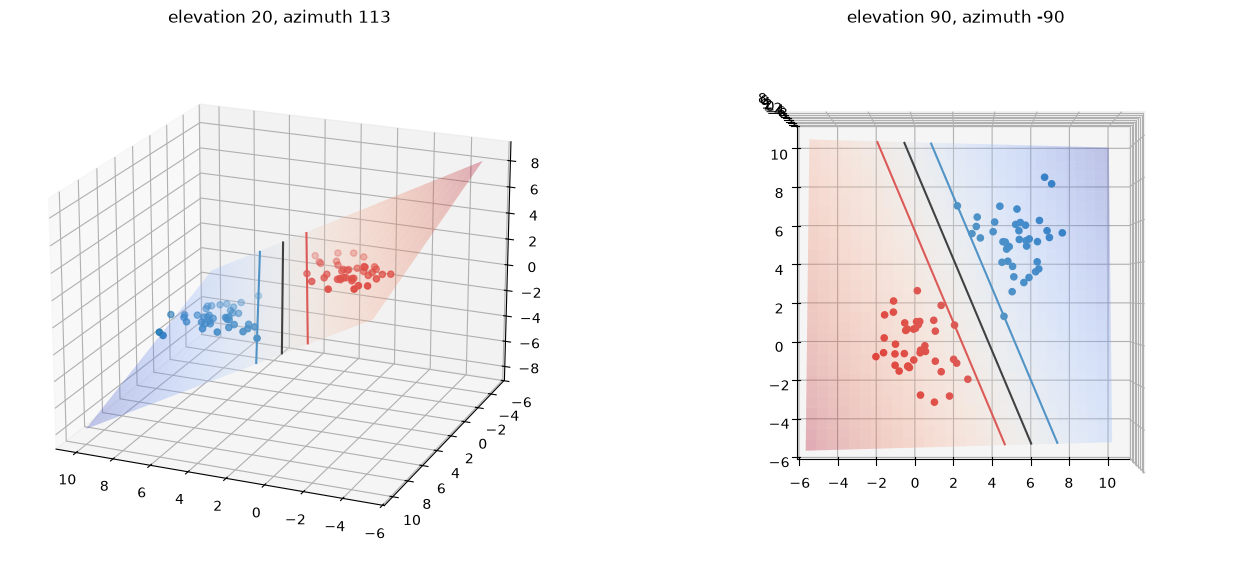

In [36]:
xx, yy = np.meshgrid(np.linspace(-5, 10, 60), np.linspace(-5, 10, 60))
Z = svm.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

fig = plt.figure(figsize=(16, 7))
for i, (elevation, azimuth) in enumerate([(20, 113), (90, -90)]):
    ax = fig.add_subplot(1, 2, i + 1, projection="3d")
    ax.plot_surface(xx, yy, Z, cmap="coolwarm", alpha=0.3, linewidth=0)
    ax.scatter(X_svm[y_svm == 1, 0], X_svm[y_svm == 1, 1], 1, color="tab:red")
    ax.scatter(X_svm[y_svm == -1, 0], X_svm[y_svm == -1, 1], -1, color="tab:blue")
    ax.contour(xx, yy, Z, levels=[-1, 0, 1], colors=["tab:blue", "k", "tab:red"])
    ax.view_init(elev=elevation, azim=azimuth)
    ax.set_title(f"elevation {elevation}, azimuth {azimuth}")
plt.show()